In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

## 1. Read data

In [2]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

#### 1. Crosstab Analysis:

- Create a crosstab between the product category and the isBestSeller status.

- Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.



In [10]:
crosstab_result = pd.crosstab(df['category'],df['isBestSeller'] )
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In general, we can observe that between in the different categories is more common not be best seller than being

But, are there some categories where be prevalent being bestseller?

In [16]:
df_bestseller = df[df['isBestSeller'] == True]['isBestSeller']

In [19]:
crosstab_result_bestseller.columns

Index([True], dtype='bool', name='isBestSeller')

In [37]:
crosstab_result_bestseller = pd.crosstab(df['category'], df['isBestSeller'] )
crosstab_result_bestseller.sort_values(by=False, ascending= False)

isBestSeller,False,True
category,,
Sports & Outdoors,835935,330
"Handmade Clothing, Shoes & Accessories",19215,14
Bath & Body,19059,33
Beauty,19010,302
Birthday Gifts,18943,35
...,...,...
Motorbike Chassis,107,0
Alexa Built-In Devices,106,1
Plugs,106,1


In [24]:

crosstab_result_bestseller = pd.crosstab(df['category'], df['isBestSeller'])


crosstab_result_bestseller['best_seller_proportion'] = crosstab_result_bestseller[True] / (
    crosstab_result_bestseller[True] + crosstab_result_bestseller[False]
)


crosstab_result_bestseller_sorted = crosstab_result_bestseller.sort_values(by='best_seller_proportion', ascending=False)


print(crosstab_result_bestseller_sorted)


isBestSeller                    False  True  best_seller_proportion
category                                                           
Grocery                          9008   556                0.058135
Smart Home Security & Lighting     98     6                0.057692
Health & Personal Care           9017   552                0.057686
Mobile Phone Accessories          248    11                0.042471
Power & Hand Tools               8353   306                0.035339
...                               ...   ...                     ...
Bedding Collections              6309     0                0.000000
CPUs                              249     0                0.000000
CD, Disc & Tape Players          8798     0                0.000000
Blank Media Cases & Wallets       243     0                0.000000
eBook Readers & Accessories       246     0                0.000000

[296 rows x 3 columns]


so we can conclude that there aren't any categorities where bing best seller prevalent.

#### 2. Statistical Tests:

- Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
- Compute Cramér's V to understand the strength of association between best-seller status and category.

In [25]:
# chi square test
from scipy.stats import chi2_contingency

# Chi-square test for 'MSZoning' and 'SaleCondition'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

p_valor = 0.0, so we reject the null hypothesis and in this way, the two categorical variables aren't independent. 
Now, to see the correlation degree we are going to study *Cramer's V*

In [27]:
# cramer 
from scipy.stats.contingency import association
association(crosstab_result, method="cramer")

0.1222829439760564

The Cramer V value of 0.1222 suggests a weak association between the two variables. 

#### 3. Visualizations:

- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [30]:
import seaborn as sns

In [40]:
dF_1 = df[df['category'] != 'Sports & Outdoors']

In [41]:
crosstab_result_1 = pd.crosstab(dF_1['category'],df['isBestSeller'] )
crosstab_result_1['total'] = crosstab_result_1[False]+crosstab_result_1[True]
crosstab_result_1.sort_values(by='total', ascending=False)

isBestSeller,False,True,total
category,,,
Beauty,19010,302,19312
"Handmade Clothing, Shoes & Accessories",19215,14,19229
Bath & Body,19059,33,19092
Birthday Gifts,18943,35,18978
Manicure & Pedicure Products,18882,58,18940
...,...,...,...
Alexa Built-In Devices,106,1,107
Motorbike Chassis,107,0,107
Plugs,106,1,107


In [ ]:
crosstab_result = pd.crosstab(df['category'],df['isBestSeller'] )
crosstab_result

<Axes: xlabel='category'>

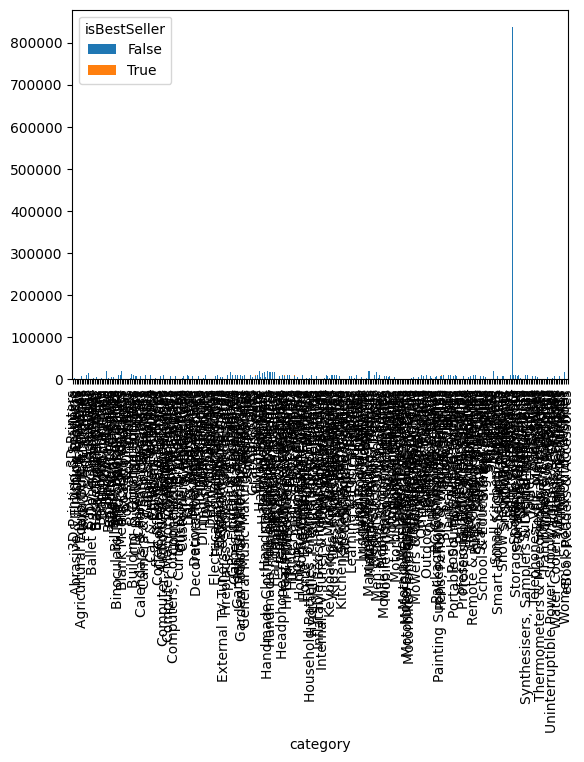

In [ ]:

crosstab_result.plot(kind="bar", stacked=True)

<Axes: xlabel='category'>

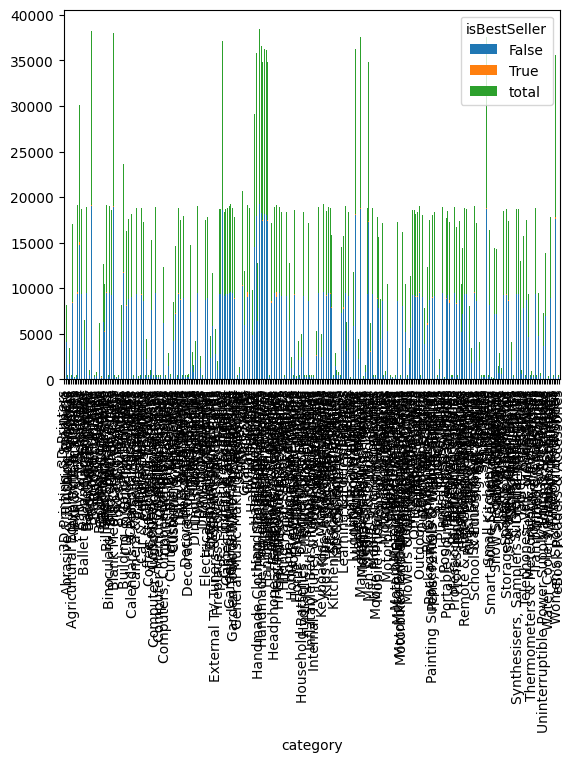

In [42]:
crosstab_result_1.plot(kind="bar", stacked=True)

<Axes: xlabel='category', ylabel='count'>

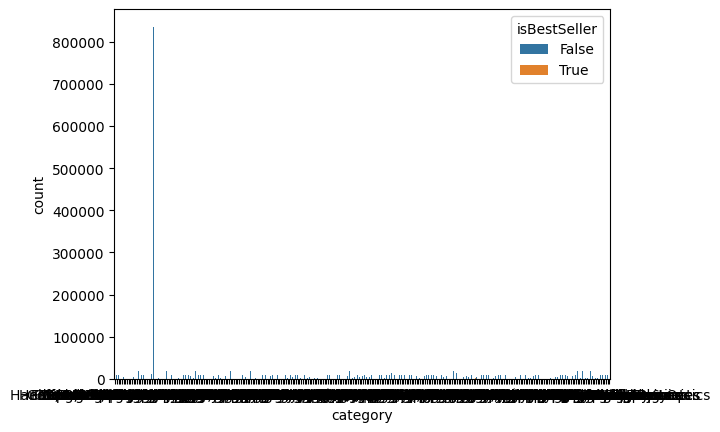

In [32]:
sns.countplot(data=df, x='category', hue='isBestSeller')

### **Part 2**: Exploring Product Prices and Ratings Across Categories and Brands

#### 0. Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

<Axes: ylabel='price'>

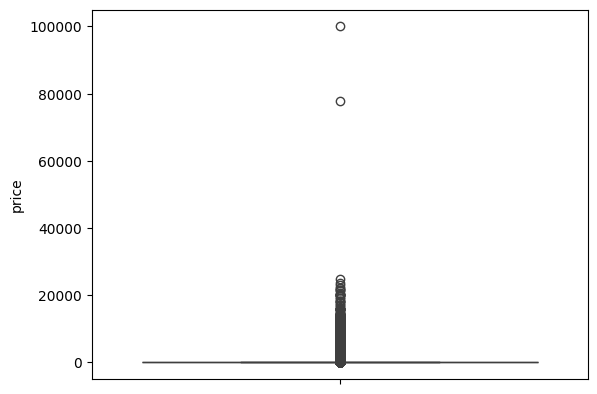

In [47]:
#boxplot

sns.boxplot(data=df, y='price')

In [44]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers

In [43]:
data_prices = df['price']

In [45]:
outliers = tukeys_test_outliers(data_prices)

In [49]:
min(outliers)

100.0

In [56]:
def eliminate_outliers(data):
    Q1 = data['price'].quantile(0.25)
    Q3 = data['price'].quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    outliers = data[(data['price'] >= lower_bound) & (data['price'] <= upper_bound)]
    
    return outliers

In [ ]:
df_1 = eliminate_outliers(df) #without outliers

In [59]:
df_1['price'].max()

np.float64(99.99)

<Axes: ylabel='price'>

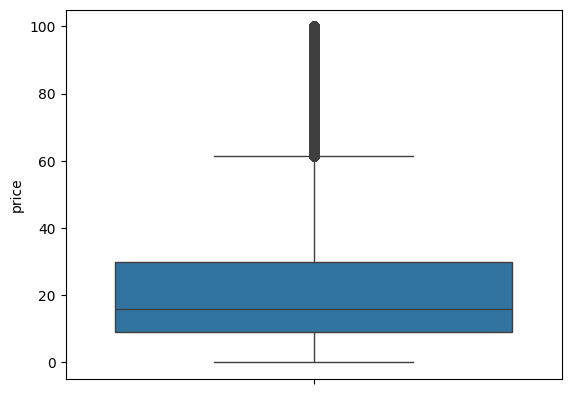

In [60]:
sns.boxplot(data=df_1, y='price')

### 1. Violin Plots:

- Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
- Which product category tends to have the highest median price? Don't filter here by top categories.

In [67]:
top_categories = df_1['category'].value_counts().head(20).index
df_top_categories = df_1[df_1['category'].isin(top_categories)]

C:\Users\Carlota\AppData\Local\Temp\ipykernel_7412\3724826285.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top_categories, x='category', y='price', palette="coolwarm")


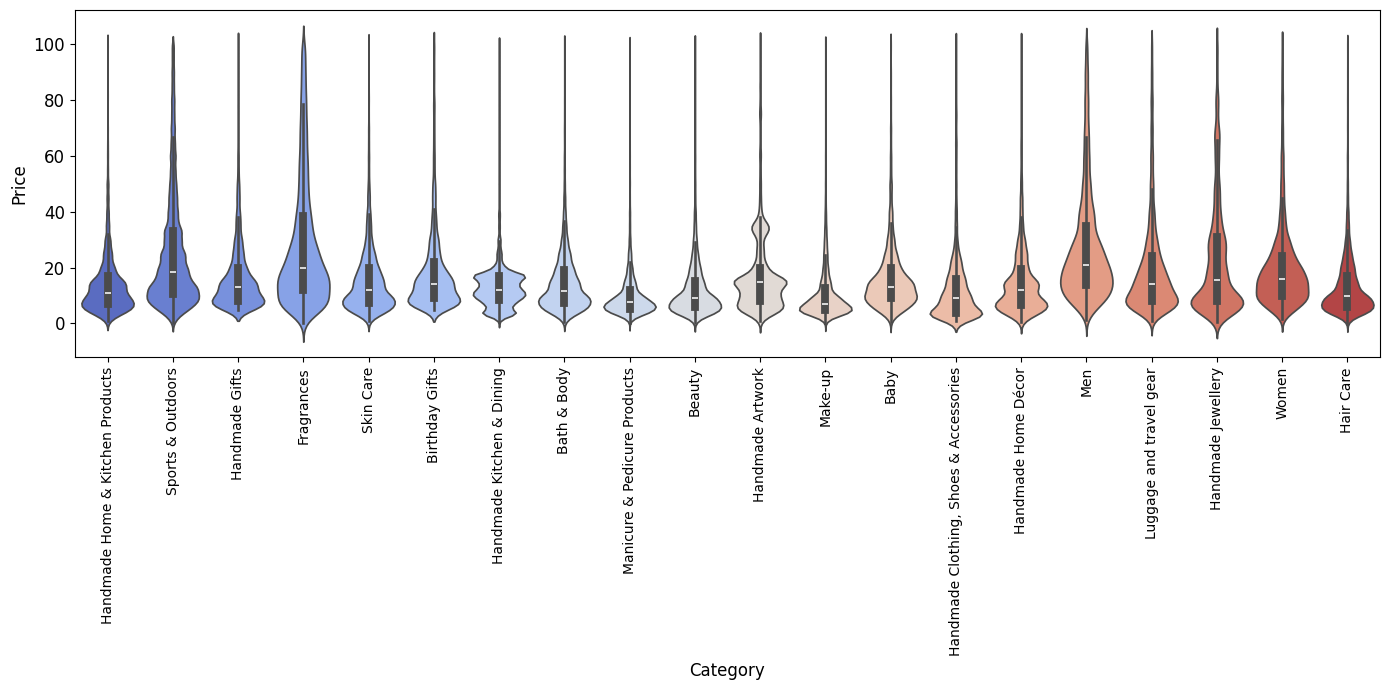

In [74]:
plt.figure(figsize=(14,7))

sns.violinplot(data=df_top_categories, x='category', y='price', palette="coolwarm")
plt.xticks(rotation=90, fontsize=10)
plt.yticks(fontsize = 12)
plt.xlabel('Category', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.tight_layout()
plt.show()

In the top 20 categories, we can observe that Men is the category with the highest median

In [77]:
median_prices = df_1.groupby('category')['price'].median().sort_values(ascending=False)
median_prices

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

the category with the hightest median is **Desktop PCs** 

#### 2. Bar Charts:

- Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
- Which product category commands the highest average price? Don't filter here by top categories.

In [78]:
top_10_categories = df_1['category'].value_counts().head(20).index
df_top_10_categories = df_1[df_1['category'].isin(top_10_categories)]

C:\Users\Carlota\AppData\Local\Temp\ipykernel_7412\2316144705.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top_10_categories, x='category', y='price', palette="coolwarm")


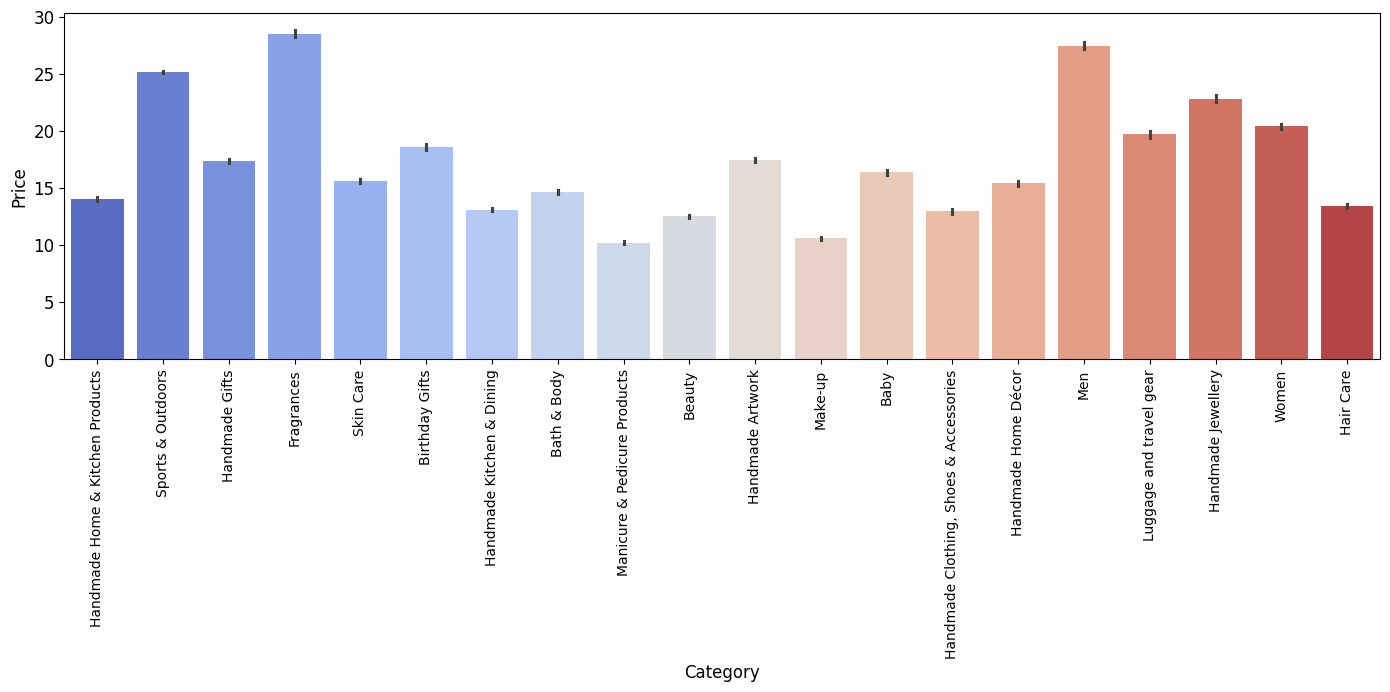

In [80]:
plt.figure(figsize=(14,7))

sns.barplot(data=df_top_10_categories, x='category', y='price', palette="coolwarm")
plt.xticks(rotation=90, fontsize=10)
plt.yticks(fontsize = 12)
plt.xlabel('Category', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.tight_layout()
plt.show()

In [81]:
avg_prices = df_1.groupby('category')['price'].mean().sort_values(ascending=False)
avg_prices

category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

the category with the highest mean is Motherboards

#### 3. Box Plots:

- Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
- Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [83]:
df_top_10_categories.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

C:\Users\Carlota\AppData\Local\Temp\ipykernel_7412\4110754974.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_10_categories, x='category', y='stars', palette="coolwarm")


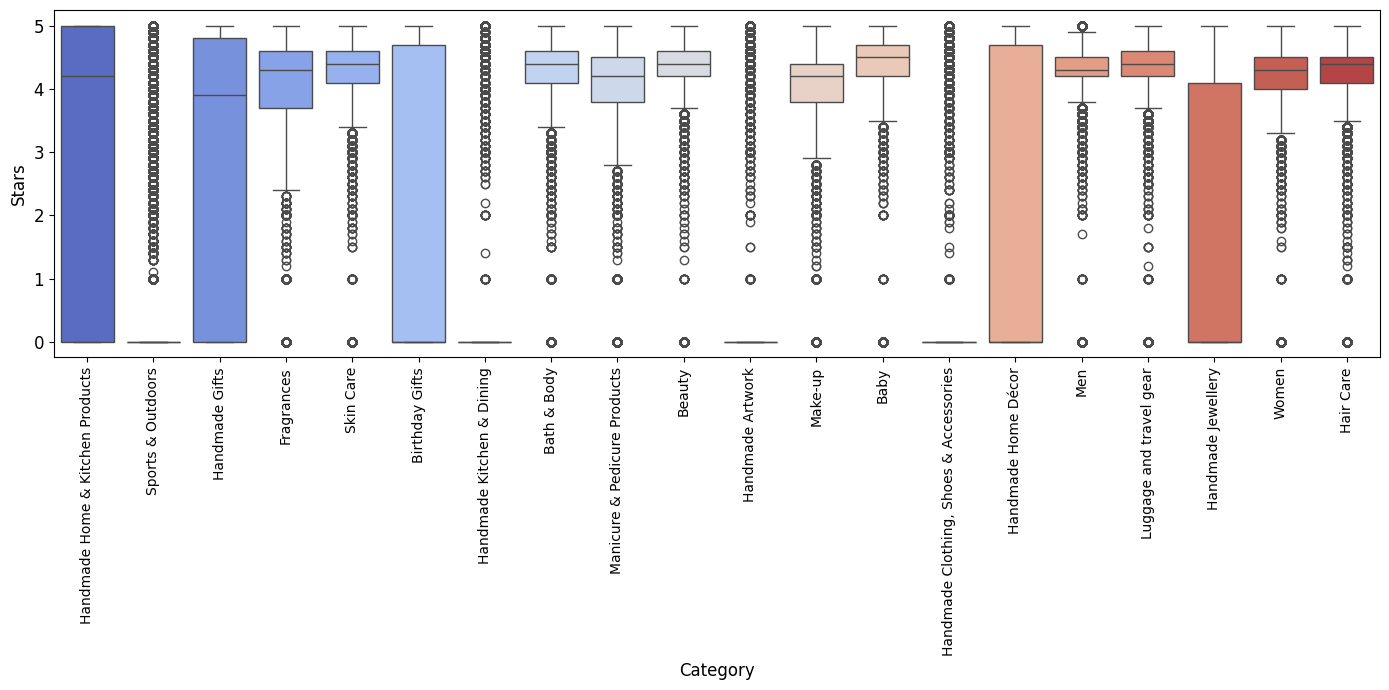

In [86]:
plt.figure(figsize=(14,7))

sns.boxplot(data=df_top_10_categories, x='category', y='stars', palette="coolwarm")
plt.xticks(rotation=90, fontsize=10)
plt.yticks(fontsize = 12)
plt.xlabel('Category', fontsize=12)
plt.ylabel('Stars', fontsize=12)
plt.tight_layout()
plt.show()

In [87]:
median_rating = df_1.groupby('category')['stars'].median().sort_values(ascending=False)
median_rating

category
Computer Memory                                 4.7
Beer, Wine & Spirits                            4.6
Building & Construction Toys                    4.6
Office Paper Products                           4.6
Kids' Play Figures                              4.6
                                               ... 
Synthesisers, Samplers & Digital Instruments    0.0
Tablets                                         0.0
Action Cameras                                  0.0
3D Printing & Scanning                          0.0
eBook Readers & Accessories                     0.0
Name: stars, Length: 296, dtype: float64

Which category tends to receive the highest median rating from customers?  **Computer Memory**

### **Part 3:** Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.



#### 1. Correlation Coefficients:

- Calculate the correlation coefficient between price and stars.
- Is there a significant correlation between product price and its rating?

In [ ]:
#pearson 
correlation = df['price'].corr(df['stars'])
correlation

np.float64(-0.12490673262148386)

In [90]:
# spearman
correlation_spearman = df['price'].corr(df['stars'], method='spearman')
correlation_spearman

np.float64(-0.13316425462433876)

due to the fact the value of both correlations are so low, there isn't any significant correlation between product price and rating

### 2. Visualizations:

- Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
- Use a correlation heatmap to visualize correlations between all numerical variables.
- Examine if product prices typically follow a normal distribution using a QQ plot.

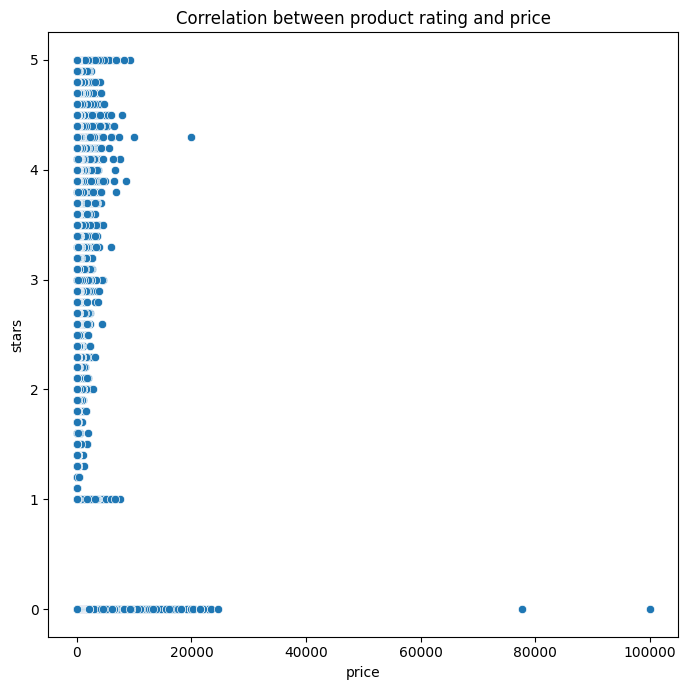

In [94]:
plt.figure(figsize=(7,7))
sns.scatterplot(data=df, x='price', y='stars')
plt.title('Correlation between product rating and price')
plt.tight_layout()
plt.show()

we can observe that the products with lower price have more reviews than products with higher prices, and in the case they had, the rating are so low. 

In [100]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [96]:
potential_categorical_from_numerical = df.select_dtypes("number").loc[:, df.select_dtypes("number").nunique() < 20]
potential_categorical_from_numerical
df_categorical = pd.concat([df.select_dtypes("object"), potential_categorical_from_numerical], axis=1)

# Adjusting the numerical dataframe by removing the moved columns
df_numerical = df.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)

In [101]:
df_numerical.drop("uid", inplace=True, axis=1)

In [102]:
df_numerical

,stars,reviews,price,boughtInLastMonth
0,4.7,15308,21.99,0
1,4.7,98099,23.99,0
2,4.7,15308,21.99,0
3,4.7,7205,31.99,0
4,4.6,1881,17.99,0
...,...,...,...,...
2443646,0.0,0,22.34,0
2443647,0.0,0,97.99,0
2443648,0.0,0,52.99,0
2443649,4.3,404,79.99,0


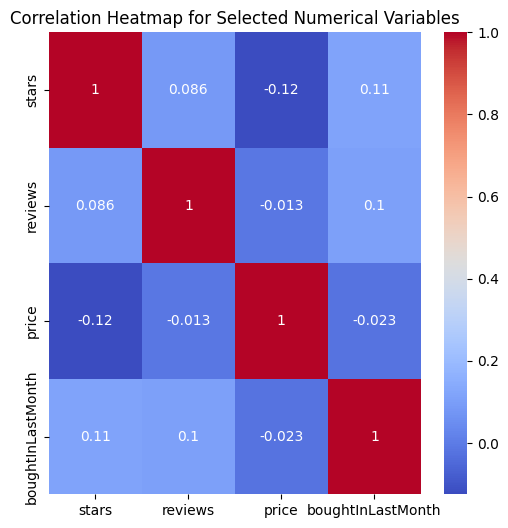

In [103]:
correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(6, 6))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

In [104]:
import statsmodels.api as sm

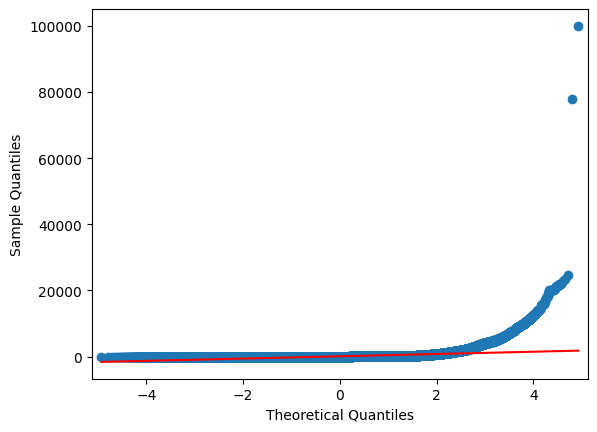

In [105]:
sm.qqplot(df['price'], line='s');

price data is not normally distributed. It appears to be right-skewed with potential outliers on the higher end and has heavier tails than a normal distribution.